In [82]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy as sp
import math
import os
from scipy import stats


%matplotlib inline

 1. ### (10 puntos) El dataset CompanyABCProfit.csv incluye los datos de la ganancia (en unidades de millones de pesos) de una cierta compañía desde el año de su fundación en 1821 hasta el año 2020. La distribución de esta ganancia tiene una forma aproximadamente normal. Suponer que se puede modelar esta distribución de una manera normal con su media y desviación estándar. Contestar lo siguiente:
 


In [83]:
## Carga de datos (archivo .csv)

mainpath = "/Users/vanotole/Documents/Doctorado/Estadistica/Datasets"
filename = "CompanyABCProfit.csv"
fullpath = os.path.join(mainpath,filename)

data = pd.read_csv(fullpath)
data.columns = ['Year','Profit']
data.head(100)  

,Year,Profit
0,1821,1645
1,1822,658
2,1823,1926
3,1824,865
4,1825,764
...,...,...
95,1916,886
96,1917,1037
97,1918,819
98,1919,1247


Text(0.5, 0, 'ganancia')

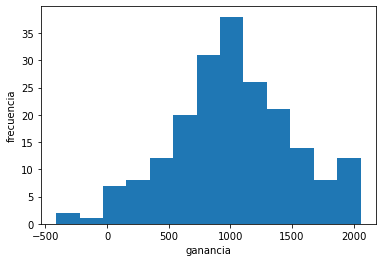

In [84]:
plt.hist(data['Profit'],bins=13)
plt.ylabel('frecuencia')
plt.xlabel('ganancia')

Se observa que estos datos tienen una forma de campana (Normal), esto es que la media, mediana y moda son muy parecidos. $N(\mu, \sigma)$
Los valores de tendecia central y de dispersión son aquellos de una población, y por tanto se llaman parámetros.

In [85]:
print(r"Media $\mu$ = ",np.mean(data['Profit']))
print(r"Mediana = ",np.median(data['Profit']))
print(r"Moda= ", data['Profit'].mode())

print('Desviacion Estándar = ',np.std(data['Profit']))
print('Varianza = ',np.var(data['Profit']))

Media $\mu$ =  1021.99
Mediana =  1024.0
Moda=  0    1082
1    1277
dtype: int64
Desviacion Estándar =  486.73420868067205
Varianza =  236910.18990000003


Ok, son un poquito desiguales, pero para efectos prácticos los podemos considerar igual. Para entender este valor de desviación estándar podemos estandarizar esta curva mediante un valor $z = \frac{x - \mu}{\sigma}$

In [86]:
data['Standard Profit'] = sp.stats.zscore(data['Profit']) ## mediante esta función es como estandarizamos

Text(0.5, 1.0, 'Distribucion Estandarizada')

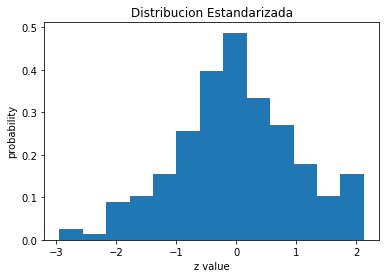

In [87]:
plt.hist(data['Standard Profit'],bins=13, density=True)
plt.xlabel('z value')
plt.ylabel('probability')
plt.title('Distribucion Estandarizada')

#### Suponiendo que esta distribución define a la población (nos interesa un año metido dentro de todos los datos pasados), ¿Cuál es la probabilidad de haber obtenido un valor menor (CDF) a la pérdida observada en 2018? 

In [90]:
profit = data[data['Year'] ==2018]['Profit']
z_value = data[data['Year'] ==2018]['Standard Profit']
prob = stats.norm.cdf(z_value)
print(prob)
print("Ganancia en 2018 : %d"%profit)
print("Z-value : %2.7f"%z_value)

print("Probabilidad usando z-value : %2.7f"%(prob*100),'%')

[0.0068432]
Ganancia en 2018 : -178
Z-value : -2.4653907
Probabilidad usando z-value : 0.6843196 %


##### Ahora, tomando esta distribución como una distribución muestral, de alguna forma se obtuvo un estimado de que en el año 2021 se tendrá una ganancia de 600 millones de pesos. En base a esta predicción, decir con un intervalo de confianza del 90 % cual sería la ganancia real en este año.

Un intervalo de confianza es el rango calculado utilizando un valor predicho $\hat{y}$, y el rango es $\hat{y} - z\frac{\sigma}{\sqrt{n}},\hat{y} + z\frac{\sigma}{\sqrt{n}}$, donde $n$ es el número de valores en nuestro dataset de población.

In [78]:
sigma = np.std(data['Profit']) # desviacion estándar de la población

N = len(data['Profit']) ### 200 observaciones
Z = stats.norm.ppf(.95) ## para encontrar z value con una cdf de 0.95 (intervalo de confianza del 90%)
profit_predicted = 600 # valor central estimado

print('z value para -178 en pérdida,',Z)

# construimos intervalo de confianza

lower_limit = profit_predicted - Z*(sigma/np.sqrt(N))
upper_limit = profit_predicted + Z*(sigma/np.sqrt(N))

print("El intervalo de confianza es [%d, %d]"%(lower_limit,upper_limit))

z value para -178 en pérdida, 1.6448536269514722
El intervalo de confianza es [543, 656]


### (10 puntos) Se quiere estudiar cómo se comporta la distancia promedio de frenado de los coches del país. ¿Cuántos autos tiene que contener una muestra estudiada (suponiendo que son escogidos totalmente al azar) para estimar el valor real de la media de frenado de la población? Se pide tener un 99 % de confianza en el estimado y que la media muestral caiga a no más de 2 metros de la media de población. Suponer que la desviación estándar de la población es de 7 metros.

Tamaño de una muestra en términos del error estándar

$n=\left (\frac{z\sigma}{m}\right)^{2}$

In [79]:
z = 2.575 # z value para construir un intervalo de confianza del 99%
sigma = 7 # desviacion estandar de 7 metros de la poblacion
m = 2 ## error estandar que se requiere


muestra_autos=((z*sigma)/m)**2
print("Los autos tiene que contener una muestra estudiada (suponiendo que son escogidos totalmente al azar) para estimar el valor real de la media de frenado de la población es=",muestra_autos)

Los autos tiene que contener una muestra estudiada (suponiendo que son escogidos totalmente al azar) para estimar el valor real de la media de frenado de la población es= 81.22515625000003


### (10 puntos) Escribir la hipótesis nula H0 y la hipótesis alternativa H1, de manera algebraica y en términos de los parámetros apropiados (μ o p).

#### El número de años que una persona trabaja antes de retirarse es 34.

$H0:\mu\neq34$ El número de años que una persona trabaja antes de retirarse es diferente a 34 años. 
<br>
$H1:\mu=34$ El número de años que una persona trabaja antes de retirarse es igual a 34 años.

#### Al menos 60 % de los mexicanos votaron en las elecciones presidenciales.

$H0:p<60$ Menos del 60% de los mexicanos votaron en las elecciones presidenciales.
<br>
$H1:p\geq 60$ Al menos 60% de lso mexicanos votaron en las elecciones presidenciales, es decir, el porcentaje de mexicanos que votaron en las elecciones presidenciales es igual o mayor de 60%.

#### El salario promedio de inicio para graduados de cierta universidad es al menos 10,000 mxn.

$H0:\mu<10,000$ El salario promedio de inicio para graduados de cierta universidad es es menor a 10,000 mxn. 
<br>
$H1:\mu\geq10,000$ El salario promedio de inicio para graduados de cierta universidad es igual o mayor a 10,000 mxn.

#### 29% de chicos de preparatoria se emborrachan cada mes

$H0:p\neq29$ El porcentaje de chicos de preparatoria que se embarrachan cada mes es diferente a 29%
<br>
$H1:p=29$ de chicos de preparatoria se emborrachan cada mes

#### El número promedio de coches que una persona tiene a lo largo de su vida es no más de 10

$H0:\mu>10$ El número promedio de coches que una persona tiene a lo largo de su vida es mayor a 10. 
<br>
$H1:\mu\leq10$ El número promedio de coches que una persona tiene a lo largo de su vida es no más de 10.


### (10 puntos) Una base de datos de los puntos de rating de distintos vinos (1-100) fue obtenida y extraída a partir de una revista y pagina web dedicada a este tema. Se encuentra que estos puntos de rating pueden ser modelados como una curva normal. Considerando esto como una población en el análisis, se tiene una media de 88.44 puntos y una desviación estándar de 3.03 puntos. Supongamos que de una muestra de n = 10 vinos se obtuvo una media muestral de puntos de 90.2. ¿Salió esta muestra de la población de vinos anterior? Escribir la prueba de hipótesis y llegar a una conclusión con un nivel de significancia del 5 % (decir si se realiza una prueba de una o dos colas).

La hipótesis nula viene dada por la población que uno supone correcta.

$H_0: \mu = 88.44$

Se conoce la $\sigma$ de población. Suponer que la media estimada de la muestras tomada de $n=10$ vinos se comporta como una gaussiana (distribución muestral de la media). En teoría esto no es válido para tan poquitas cosas pero ok. Esta distribución tiene una media de $\mu_{\bar{x}} = \mu$ y una desviación estándar dada por $\sigma_{\bar{x}} = \frac{\sigma}{\sqrt{n}} $. Se hace una prueba de hipótesis con una estadística de prueba Z para corroborar.

$\frac{\overline{X}-\mu_0}{\sigma/\sqrt{n}}<Z_{\alpha}$, el z calculado tiene que ser menor a cierto valor crítico $Z_{\alpha}$. Para un nivel de significancia del 5% (nivel de confianza del 95% para una prueba de dos colas, cada cola tiene una región critca con 2.5% de probabilidad), este valor crítico es $Z = 1.96$.

In [80]:
## valor critico

z_crit = stats.norm.ppf(0.975) ## recordar que para obtener un cdf tiene que darle un z value

print('z critico =', z_crit)


z critico = 1.959963984540054


La estadística de prueba para esta distribución Z es $\frac{\bar{x} - \mu}{\sigma/\sqrt{n}}$

In [81]:
## estadistica de prueba

n= 10 # tamaño de la muestra

x_muestra = 90.2 # media de muestra

mu = 88.44 # media de poblacion

sigma = 3.03 # desviacion estandar de poblacion

z_prueba = (x_muestra - mu)/(sigma/np.sqrt(n))

print(sigma/np.sqrt(n))
print('Estadistica z de prueba = ', z_prueba)
print('Valor z critico =', z_crit)

0.9581701310310188
Estadistica z de prueba =  1.8368345484806485
Valor z critico = 1.959963984540054


La media de 90.2 puntos se encuentra a 1.83 desviaciones estándar de la media de poblacion, pero aún así esta dentro de lo razonable dado el z crítico. No se tienen argumentos para rechazar la hipótesis nula, y esta muestra de vinos podría ser tomada de la misma de la población con mu = 88.44 y desviacion estandar de 3.03.

### (10 puntos) Una encuesta de 430 adultos escogidos al azar encuentra que 21 % de 222 hombres y 18 % de 208 mujeres han hecho compras en línea el año pasado. ¿Existe evidencia para decir que los hombres están más inclinados que las mujeres a realizar compras en línea? Escribir la hipótesis nula y alternativa, calcular la estadística de prueba apropiada, y utilizar una significancia del 5 % para sacar una conclusión.

Escribimos las hipótesis

$H0: p_H \le p_M$ los hombres están igual o menos inclinados que las mujeres a realizar compras en línea 
<br>
$H1: p_H > p_M $ Los hombres están más inclinados que las mujeres a realizar compras en línea

Se trata de una prueba de hipótesis para una diferencia de proporciones, de una sola cola. (También podrían hacer la prueba de dos colas, si así se requiere)

$\hat{p}_H = 0.21$ de una muestra de $n_H = 222$ para hombres 


$\hat{p}_M = 0.18$ de una muestra de $n_M = 208$ para mujeres 

Son muestras y sus proporciones siguen el teorema del límite central para proporciones. Se trata de una prueba de hipótesis con distribucion Z, donde las desviaciones se estiman con las proporciones observadas. La estadistica de prueba es la siguiente

$Z = \frac{\hat{p}_H - \hat{p}_M}{\sqrt{pq(\frac{1}{n_H} + \frac{1}{n_M})}}$

donde $p$ en este caso actúa como la probabilidad de hacer una compra en línea, tanto para hombres como para mujeres, para la población. Estos valores de poblacion no se conocen, pero el mejor estimado que tenemos, $\hat{p}$ es el siguiente, considerando las dos proporciones:

$\hat{p} = \frac{n_M \hat{p}_M + n_H\hat{p}_H}{n_H + n_M}$

Ya con esto se puede calcular la estadística de prueba Z, y compararla con un valor crítico . En la ecuación de la estadistica de prueba habría que estimar los valores de $p$ y de $q$ con aquellos de $\hat{p}$ y de $\hat{q} = 1 - \hat{p}$. $\hat{q}$ sería la probabilidad de no hacer una compra.

Para una prueba de una sola cola, con un nivel de significancia del 5%, se trata de un nivel de confianza del 90%, cuyo valor crítico es


In [91]:
## valor critico

z_crit = stats.norm.ppf(0.95) ## recordar que para obtener un cdf tiene que darle un z value

print('z critico =', z_crit)

z critico = 1.6448536269514722


In [92]:
## estadistica de prueba

p_H = 0.21
n_H = 222

p_M = 0.18
n_M = 208

p_estimada = (n_M*p_M + n_H*p_H) / (n_H + n_M)
q_estimada = 1 - p_estimada

print(p_estimada)

z_prueba = (p_H - p_M) / (np.sqrt(p_estimada*q_estimada*( (1/n_H) + (1 / n_M) )))

print('Estadistica z de prueba = ', z_prueba)
print('Valor z critico =', z_crit)

0.19548837209302325
Estadistica z de prueba =  0.7839142404580844
Valor z critico = 1.6448536269514722


La z de prueba no es mayor que la z crítica, por lo que no hay evidencia estadística para rechazar la hipótesis nula. Hay argumentos para pensar que tanto los hombres como las mujeres tienen una probabilidad similar de hacer compras en línea, considerando estos datos. O dicho de otra forma, no hay argumentos para decir que los hombres compran más en en línea que las mujeres.

### (10 puntos) En una prueba t de una sola muestra se compara una media muestral con respecto a un valor de la hipótesis nula. De manera similar, en una prueba t para muestras dependientes apareadas se calcula la diferencia entre las observaciones pareadas (ejemplo: observaciones antes y después en una sola muestra) y después se realiza una prueba t de una sola muestra a estas diferencias. En la tabla 1 se muestran las calificaciones de 20 estudiantes antes y después de llevar un curso de preparación. Se quiere buscar si en general este curso mejoró la capacidad de los estudiantes para realizar este examen. Realizar la prueba t pareada para esta muestra de estudiantes calculando cada uno de los siguiente incisos:

In [49]:
## se crea una data frame con los datos

data = pd.DataFrame(
{
    'numero de estudiante':[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20],
    'calificacion_antes':[18,21,16,22,19,24,17,21,23,18,14,16,16,19,18,20,12,22,15,17],
    'calificacion_despues':[22,25,17,24,16,29,20,23,19,20,15,15,18,26,18,24,18,25,19,16]
}
)

data

,numero de estudiante,calificacion_antes,calificacion_despues
0,1,18,22
1,2,21,25
2,3,16,17
3,4,22,24
4,5,19,16
5,6,24,29
6,7,17,20
7,8,21,23
8,9,23,19
9,10,18,20


#### Calcular la diferencia di entre las dos observaciones de cada para, haciendo la distin- ci ́on entre diferencias negativas y positivas.

In [50]:
## agregamos columna de diferencias

data['diferencias'] = data['calificacion_despues'] - data['calificacion_antes']

data

,numero de estudiante,calificacion_antes,calificacion_despues,diferencias
0,1,18,22,4
1,2,21,25,4
2,3,16,17,1
3,4,22,24,2
4,5,19,16,-3
5,6,24,29,5
6,7,17,20,3
7,8,21,23,2
8,9,23,19,-4
9,10,18,20,2


#### Calcular la media de la distribuci ́on de estas diferencias, d.

In [53]:
# calculamos la media de esta columna

d_barra = data['diferencias'].mean()
print('la media de las diferencias =', d_barra)

la media de las diferencias = 2.05


#### Calcular la desviación estándar de estas diferencias, $s_d$, y utilizar esto para calcular el error estándar de la distribución muestral asociada $SE(\bar{d}) = \frac{s_d}{\sqrt{n}}$

In [58]:
### calculamos la desviacione estandar de las diferencias

s_d = data['diferencias'].std()
print('desviacion estandar de las diferencias = ',s_d)

## calculamoes error estandar de la distribucion muestral de esta media de diferencias

n = 20 # tamaño de la muestra

SE_d = s_d / np.sqrt(n)

print('Error estándar de la distribucion = ', SE_d)

desviacion estandar de las diferencias =  2.8372521918222215
Error estándar de la distribucion =  0.634428877022476


#### En la hipótesis nula se tendría que las diferencias antes y después sean cero ($H_0: \bar{d} \le 0$). Lo que nosotros queremos estudiar (alternativa) es si estas diferencias son mayores $H_1: \bar{d} > 0$. Entonces , esto sería con una prueba de una sola cola. Aquí no se tiene una desviación estándar de población, por lo que se utiliza una prueba de hipótesis con una distribución t de Student. En este caso la estadística de prueba se calcula con la siguiente ecuación:

$t = \frac{\bar{d}}{SE(\bar{d})}$



In [59]:
# calculo de la estadística de prueba

t_test = (d_barra) / SE_d

print('Estadistica t de prueba = ', t_test)

Estadistica t de prueba =  3.2312526655803127


#### Esta estadística de prueba para una distribución t de Student tiene los grados de libertad de la única muestra analizada $df = n - 1 = 20 - 1= 19$.  Si consideramos un nivel de significancia del 5% para una prueba de una colar (nivel de confianza del 90%) la t crítica correspondiente para esta distribución es la siguiente


In [61]:
df = 19 ## grados de libertad

## valor critico

t_crit = stats.t.ppf(0.95,df) # nivel de confianza del 90 corresponde a un CDF de 95%

print('z critico =', t_crit)

z critico = 1.729132811521367


La estadística de prueba es mayor a la t crítica para esta distribución t student con 19 grados de libertad. Tenemos evidencia estadística para rechazar la hipótesis nula. Se tiene evidencia para decir que el curso de preparación tiene un impacto estadísticamente significativo en el aumento de la nota en el examen.

1.7291328115213678


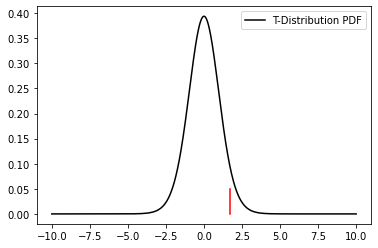

In [62]:
## Basic T-Distribution
import scipy.stats as st
import matplotlib.pyplot as plt
import numpy as np

## Setup      
dof = 19        # Degrees of freedom
alpha = 0.05    # Significence level
ntails = 1      # Number of tails 

## Calculate critical t-score
tcrit = abs(st.t.ppf(alpha/ntails, dof))
# +=2.068
print(tcrit)

plt.figure()
xs = np.linspace(-10,10,1000)
plt.plot(xs, st.t.pdf(xs,dof), 'k', label="T-Distribution PDF")

## Plot some vertical lines representing critical t-score cutoff
critline = np.linspace(0,alpha/ntails)  # y range for critical line, AKA probability from 0-p*
xs_1 = len(critline) * [-tcrit]         # X ranges for plotting
xs_2 = len(critline) * [tcrit]
#plt.plot(xs_1, critline, 'r')
plt.plot(xs_2, critline,'r')
plt.legend()